### Continuous Least Squares Approximation

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate

In [32]:
# Define the continuous function to approximate
f = lambda x: np.exp(5*x)
# f = lambda x: x**3

In [33]:
# Define the interval
a, b = 0, 1

In [34]:
# Degrees of polynomial approximation
degrees = [1, 2, 3]    # Linear, Quadratic and Cubic

In [35]:
# Basis function generator
def basis_funcs(n):
  return [lambda x, i=i: x**i for i in range(n+1)]

Least Squares Polynomial Coefficients (Degree 1)
c0 = -24.786105
c1 = 108.537475

Least Squares Polynomial Coefficients (Degree 2)
c0 = 14.089579
c1 = -124.716633
c2 = 233.254107

Least Squares Polynomial Coefficients (Degree 3)
c0 = -3.685558
c1 = 88.585010
c2 = -300.000000
c3 = 355.502738



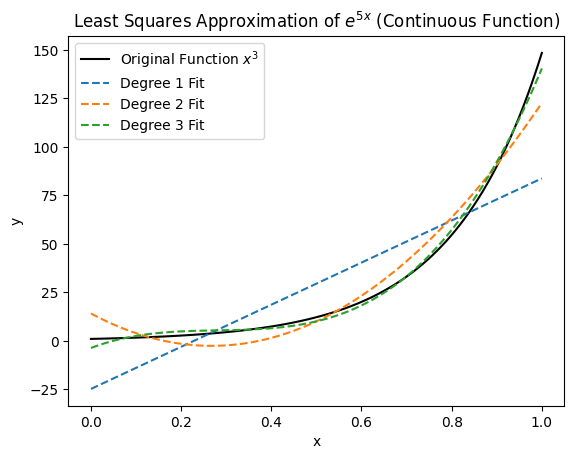

In [36]:
# Plot original function
x_vals = np.linspace(a, b, 100)
y_vals = f(x_vals)
# plt.plot(x_vals, y_vals, label='Original Function $e^x$', color='black')
plt.plot(x_vals, y_vals, label='Original Function $x^3$', color='black')
# Perform Lease Squares approximation for each degree
for n in degrees:
  basis = basis_funcs(n)
  A = np.zeros((n+1, n+1))
  b_vec = np.zeros(n+1)
  for i in range(n+1):
    for j in range(n+1):
      A[i, j], _ = integrate.quad(lambda x: basis[i](x) * basis[j](x), a, b)
    b_vec[i], _ = integrate.quad(lambda x: f(x) * basis[i](x), a, b)
  # Solve for coefficients
  c = np.linalg.solve(A, b_vec)
  # Construct the approximation function
  P_n = lambda x: sum(c[i] * basis[i](x) for i in range(n+1))
  # Plot the approximation
  y_approx = P_n(x_vals)
  plt.plot(x_vals, y_approx, linestyle='dashed', label=f'Degree {n} Fit')
  # Print coefficients
  print(f'Least Squares Polynomial Coefficients (Degree {n})')
  for i, coeff in enumerate(c):
    print(f'c{i} = {coeff:.6f}')
  print()
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Least Squares Approximation of $e^{5x}$ (Continuous Function)')
# plt.title('Least Squares Approximation of $x^3$ (Continuous Function)')
plt.show()